# Diabetes Analysis: EDA, CCA, and SVM

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cross_decomposition import CCA
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix


In [2]:

df = pd.read_csv("diabetes.csv")

print(df.head())
print(df.describe())


   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  
       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  120.894531      69.105469      20.536458   79.799479   
std       3.369578   31.972618      19.355807      15.952218  115.244002   

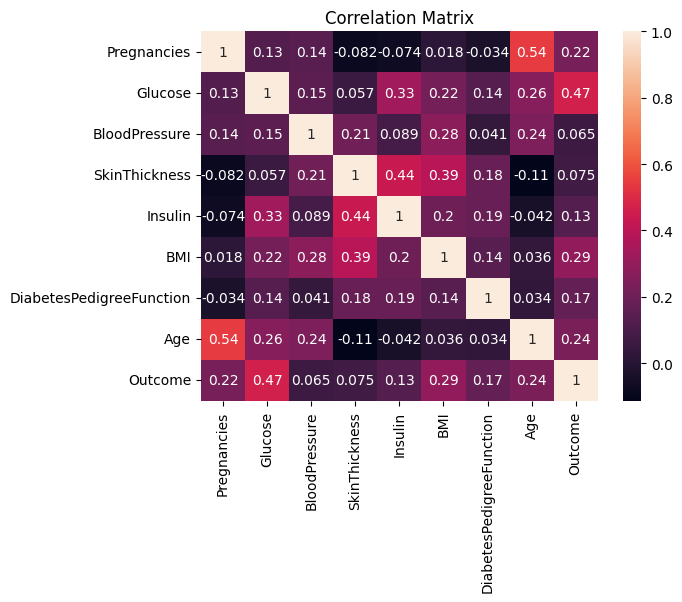

In [3]:

plt.figure()
sns.heatmap(df.corr(), annot=True)
plt.title("Correlation Matrix")
plt.show()


In [4]:

X = df.iloc[:, :-1]
y = df.iloc[:, -1]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [5]:

X1 = X_scaled[:, :4]
X2 = X_scaled[:, 4:]

cca = CCA(n_components=2)
X1_c, X2_c = cca.fit_transform(X1, X2)

print("Canonical Correlations:")
print(np.corrcoef(X1_c.T, X2_c.T))


Canonical Correlations:
[[1.00000000e+00 5.07577275e-18 6.49420235e-01 2.81771558e-17]
 [5.07577275e-18 1.00000000e+00 5.00358926e-04 6.03756627e-01]
 [6.49420235e-01 5.00358926e-04 1.00000000e+00 1.23587358e-16]
 [2.81771558e-17 6.03756627e-01 1.23587358e-16 1.00000000e+00]]


In [6]:

model = SVC(kernel='linear')
model.fit(X_scaled, y)

y_pred = model.predict(X_scaled)

acc = accuracy_score(y, y_pred)
print("Accuracy:", acc)

cm = confusion_matrix(y, y_pred)
print("Confusion Matrix:\n", cm)


Accuracy: 0.7734375
Confusion Matrix:
 [[442  58]
 [116 152]]
